# Ottimizzazione numerica

###  Introduzione

L’ottimizzazione è il settore della matematica che studia come individuare la soluzione migliore tra tutte quelle possibili. In termini matematici, questo significa spesso determinare il punto in cui una funzione assume il suo valore minimo o massimo. I problemi di minimo sono particolarmente importanti perché molte situazioni reali possono essere descritte come la ricerca della configurazione che riduce al minimo un costo, un errore, un consumo di risorse o una distanza rispetto a un obiettivo.

Esempi di problemi di ottimizzazione compaiono in moltissimi ambiti. Nell’ingegneria si cerca di progettare strutture efficienti e resistenti utilizzando la minore quantità possibile di materiale. Nella logistica si vogliono ridurre i tempi e i costi di trasporto. Nell’elaborazione delle immagini si cerca una ricostruzione che sia allo stesso tempo fedele ai dati osservati e priva di rumore. In economia si ottimizzano profitti, investimenti e allocazione delle risorse.

L’ottimizzazione riveste un ruolo centrale anche nell’analisi dei dati, nel machine learning e nelle reti neurali. In questi contesti si introduce generalmente una funzione di costo, o funzione di perdita, che misura quanto le previsioni del modello siano lontane dai valori desiderati. Addestrare un modello significa quindi trovare i valori dei suoi parametri che rendono questa funzione il più piccola possibile.

Nel caso di una rete neurale, i parametri da determinare sono i pesi e i bias dei diversi strati. Poiché il loro numero può essere molto elevato, il problema di ottimizzazione è generalmente multidimensionale. Il gradiente della funzione di costo indica la direzione in cui la funzione cresce più rapidamente; muovendosi nella direzione opposta si cerca quindi di ridurne il valore. Questa idea è alla base del metodo del gradiente discendente e di molti degli algoritmi utilizzati per l’addestramento delle reti neurali.

Lo studio del gradiente, della matrice hessiana e delle derivate di funzioni di più variabili permette quindi non solo di descrivere il comportamento locale di una funzione, ma anche di costruire metodi numerici in grado di individuare in modo efficiente punti di minimo.


Data una funzione 

$$ 
f:\Omega \subset R^n \rightarrow R 
$$ 

matematicamente il problema si formula come un problema di minimo.

$$
argmin_{x \in \Omega} f(x)
$$ 

oppure di massimo:

$$
argmax_{x \in \Omega} f(x)
$$

cioè si ricerca l'ascissa del punto di minimo o di massimo della funzione.

I due problemi sono equivalenti semplicemente cambiando il segno della funzione, cioè se $f(x)$ è continua e limitata, 

$$
argimn_{x \in \Omega} f(x)=argmax_{x \in \Omega} -f(x).
$$ 

Quindi di solito si studia solo il problema di minimizzare una funzione, al quale ci si può sempre facilmente ricondurre.

L’insieme $\Omega$, spesso detto insieme dei valori accettabili o insieme dei vincoli, descrive sotto quali ipotesi la soluzione 
 del problema deve sottostare per essere dichiarata accettabile.

```{note}
Quanto appena descritto rappresenta un procedimento chiamato **modellizzazione matematica**, in cui un processo viene descritto matematicamente assegnando delle variabili e delle funzioni ai vari elementi del processo. Questo tipo di approccio è tipico di praticamente qualunque applicazione, ed è necessario prenderci la mano per capire bene il resto del corso.
```

In base alla forma dell'insieme $\Omega$ dei vincoli, oltre che alle proprietà matematiche della funzione obiettivo $f(x)$, i problemi di ottimizzazione si classificano in varie categorie. 

Partendo dalla scelta di $\Omega$, riconosciamo due classi principali:

* Se $\Omega = \mathbb{R}^n$, allora diciamo che il problema è **non vincolato** (*unconstrained*, in Inglese)
* Se $\Omega \subset \mathbb{R}^n$, allora diciamo che il problema è **vincolato** (*constrained*, in Inglese)

Ulteriori classificazioni si hanno considerando altre proprietà della funzione obiettivo. Ad esempio:

* Se $f(x) = x^T w$ è una funzione lineare in $x$, allora il problema è detto **lineare**,
* Se $f(x) = x^T A x + x^T b$ è una funzione quadratica in $x$, allora il problema è detto **quadratico**.

```{note}
In questo corso tratteremo ottimizzazione non vincolata.
```

###  Definizioni: punti di minimo

-  $x^*$ è un punto di **minimo locale** di $f(x)$ se
esiste un $\epsilon>0$ tale

 $$f(x^*)\leq f(x) \quad \text{per ogni } x \text{ tale che }
    \|x-x^*\|<\epsilon$$

- $x^*$ è un punto di **minimo locale in senso
stretto** di $f(x)$ se esiste un $\epsilon>0$ tale

$$f(x^*) < f(x) \quad \text{per ogni }  x \text{ tale che }
    \|x-x^*\|<\epsilon, \quad x\neq x^*$$

-  $x^*$ è un punto di **minimo globale** di $f(x)$ se

$$f(x^*)\leq f(x) \quad \text{per ogni } x \in {R}^n$$

- $x^*$ è un punto di **minimo globale in senso
stretto** di $f(x)$ se

$$f(x^*) < f(x) \quad \text{per ogni } x \in {R}^n, \quad x\neq x^*$$

*Esempi di minimi*

Una funzione $f$ può avere un punto di minimo locale e tuttavia non avere un punto di minimo globale. Può inoltre non avere né minimi locali né globali, oppure avere sia minimi locali sia minimi globali.

![](immagini_sorgente/ott1.png)

<!-- ```{figure} immagini_sorgente/ott1.png
---
width: 90%
align: center
---
```

<p align="center">
  <img src="immagini_sorgente\ott1.png"  width="800"> -->
 

- $y=(x-x^*)^2$: un unico punto di minimo;
- $y=-2\cos(x-x^*)$: molti punti di minimo globale;
- $y=0.015(x-x^*)^2-2\cos(x-x^*)$: un punto di minimo globale e molti punti di minimo locale.




La figura seguente distingue graficamente minimi locali, minimi locali stretti e un minimo globale stretto.
<!-- 
```{figure} immagini_sorgente/fig4m.png
---
width: 70%
align: center
---
```
<p align="center">
  <img src="immagini_sorgente\fig4m.png"  width="700"> -->





I punti di massimo locale e globale di $f$ sono definiti in maniera analoga ai punti di minimo.




**Funzione differenziabile**

Una funzione $f:\mathbb{R}^n\to\mathbb{R}$ si dice **differenziabile** in un punto $\mathbf{x}^*\in\mathbb{R}^n$ se esiste un'applicazione lineare $L:\mathbb{R}^n\to\mathbb{R}$ tale che

$$
\lim_{\mathbf{h}\to\mathbf{0}}
\frac{f(\mathbf{x}^*+\mathbf{h})-f(\mathbf{x}^*)-L(\mathbf{h})}
{\lVert\mathbf{h}\rVert}
=0.
$$

Una funzione $f:\mathbb{R}^n\to\mathbb{R}$ si dice differenziabile in un insieme $\Omega\subset\mathbb{R}^n$ se è differenziabile in ogni punto di $\Omega$.

**Proprietà**

- Se $f$ è differenziabile in $\mathbf{x}^*$, tutte le derivate parziali di $f$ in $\mathbf{x}^*$ esistono.
- Se $f$ è differenziabile in $\mathbf{x}^*$, allora $f$ è continua in $\mathbf{x}^*$.


 *Condizioni di ottimalità*

- Una **condizione di ottimalità** è una condizione affinché un punto $\mathbf{x}^*$ risulti una soluzione ottima, locale o globale, del problema.
- Una condizione di ottimalità è significativa se è più semplice da verificare della definizione stessa.
- Le condizioni di ottimalità si esprimono tipicamente mediante sistemi di equazioni, disequazioni oppure condizioni sugli autovalori di matrici opportune.

Lo studio delle condizioni di ottimalità è interessante sia dal punto di vista teorico sia da quello algoritmico.


**Condizione necessaria del primo ordine**

 **Teorema.** Se $\mathbf{x}^*$ è un punto di minimo locale e $f$ è differenziabile con continuità in un intorno aperto di $\mathbf{x}^*$, allora

 $$
 \nabla f(\mathbf{x}^*)=\mathbf{0}.
 $$

Un punto $\mathbf{x}^*$ tale che $\nabla f(\mathbf{x}^*)=\mathbf{0}$ è detto **punto stazionario**. Pertanto,

$$
\mathbf{x}^*\text{ punto di minimo locale}
\quad\Longrightarrow\quad
\mathbf{x}^*\text{ punto stazionario}.
$$

La condizione $\nabla f(\mathbf{x}^*)=\mathbf{0}$ non è sufficiente: un punto stazionario può essere un punto di minimo locale, un punto di massimo locale oppure un punto di sella.

![](immagini_sorgente/fig7m.png)

<!-- ```{figure} immagini_sorgente/fig7m.png
---
width: 100%
align: center
---
```
<p align="center">
  <img src="immagini_sorgente\fig7m.png"  width="900">
</p> -->



*Matrici definite positive*

Una matrice simmetrica $A\in\mathbb{R}^{n\times n}$ si dice:

- **definita positiva** se

  $$
  \mathbf{x}^{T}A\mathbf{x}>0
  \qquad\forall\,\mathbf{x}\in\mathbb{R}^n\setminus\{\mathbf{0}\};
  $$

- **semidefinita positiva** se

  $$
  \mathbf{x}^{T}A\mathbf{x}\geq0
  \qquad\forall\,\mathbf{x}\in\mathbb{R}^n;
  $$

- **definita negativa** se

  $$
  \mathbf{x}^{T}A\mathbf{x}<0
  \qquad\forall\,\mathbf{x}\in\mathbb{R}^n\setminus\{\mathbf{0}\};
  $$

- **semidefinita negativa** se

  $$
  \mathbf{x}^{T}A\mathbf{x}\leq0
  \qquad\forall\,\mathbf{x}\in\mathbb{R}^n;
  $$

- **indefinita** se esistono $\mathbf{x}_1,\mathbf{x}_2\in\mathbb{R}^n$ tali che

  $$
  \mathbf{x}_1^TA\mathbf{x}_1>0,
  \qquad
  \mathbf{x}_2^TA\mathbf{x}_2<0.
  $$


*Caratterizzazione mediante gli autovalori*

Per una matrice simmetrica valgono le seguenti proprietà equivalenti:

- una matrice definita positiva ha tutti gli autovalori positivi;
- una matrice semidefinita positiva ha tutti gli autovalori non negativi;
- una matrice definita negativa ha tutti gli autovalori negativi;
- una matrice semidefinita negativa ha tutti gli autovalori non positivi;
- una matrice indefinita ha alcuni autovalori positivi e altri negativi.


**Condizioni necessarie del secondo ordine**

 **Teorema.** Se $\mathbf{x}^*$ è un punto di minimo locale di $f$ e $f$ è due volte differenziabile con continuità in un intorno aperto di $\mathbf{x}^*$, allora

 $$
 \nabla f(\mathbf{x}^*)=\mathbf{0}
 \qquad\text{e}\qquad
 \nabla^2 f(\mathbf{x}^*) \geq 0.
 $$

Pertanto,

$$
\mathbf{x}^*\text{ punto di minimo locale}
\quad\Longrightarrow\quad
\begin{cases}
\mathbf{x}^*\text{ è un punto stazionario},\\
\nabla^2 f(\mathbf{x}^*)\text{ è semidefinita positiva}.
\end{cases}
$$


**Condizioni sufficienti del secondo ordine**

 **Teorema.** Sia $f$ due volte differenziabile con continuità in un intorno aperto di $\mathbf{x}^*$ e supponiamo che $\nabla f(\mathbf{x}^*)=\mathbf{0}$.

 - Se $\nabla^2f(\mathbf{x}^*)$ è definita positiva, allora $\mathbf{x}^*$ è un punto di minimo locale in senso stretto.
 - Se $\nabla^2f(\mathbf{x}^*)$ è definita negativa, allora $\mathbf{x}^*$ è un punto di massimo locale in senso stretto.
 - Se $\nabla^2f(\mathbf{x}^*)$ è indefinita, allora $\mathbf{x}^*$ è un punto di sella.

In particolare,

$$
\left.
\begin{array}{l}
\nabla f(\mathbf{x}^*)=\mathbf{0},\\
\nabla^2f(\mathbf{x}^*)>0
\end{array}
\right\}
\quad\Longrightarrow\quad
\mathbf{x}^*\text{ è un minimo locale stretto}.
$$


*Osservazioni*

- Le condizioni sufficienti del secondo ordine garantiscono qualcosa di più forte delle condizioni necessarie: garantiscono che $\mathbf{x}^*$ è un punto di minimo locale **stretto**.
- Le condizioni sufficienti del secondo ordine non sono necessarie.
- Esiste un divario tra le condizioni necessarie e quelle sufficienti nel caso in cui

  $$
  \nabla f(\mathbf{x}^*)=\mathbf{0}
  \qquad\text{e}\qquad
  \nabla^2f(\mathbf{x}^*)\geq0.
  $$

- Possono esistere punti che soddisfano le condizioni necessarie del primo e del secondo ordine ma non sono punti di minimo locale.

Le funzioni $x^2$, $x^3$ e $-x^4$ mostrano come un Hessiano nullo nel punto stazionario non sia sufficiente per classificare il punto.



### Tipi di punti stazionari

La forma locale della superficie dipende dalla definitezza dell'Hessiano:

- Hessiano definito positivo: funzione localmente convessa, minimo;
- Hessiano definito negativo: funzione localmente concava, massimo;
- Hessiano indefinito: curvature di segno opposto, punto di sella.

![](immagini_sorgente/fig6m.png)

<!-- <p align="center">
  <img src="immagini_sorgente\fig6m.png"  width="800">
</p>

```{figure} immagini_sorgente/fig6m.png
---
width: 80%
align: center
---
``` -->

###  Il caso convesso


Una funzione $f$ è **convessa** in $\mathbb{R}^n$ se

$$
f\bigl(\alpha\mathbf{x}+(1-\alpha)\mathbf{y}\bigr)
\leq
\alpha f(\mathbf{x})+(1-\alpha)f(\mathbf{y})
$$

per ogni $\alpha\in[0,1]$ e per ogni $\mathbf{x},\mathbf{y}\in\mathbb{R}^n$.

La funzione $f$ è **strettamente convessa** se

$$
f\bigl(\alpha\mathbf{x}+(1-\alpha)\mathbf{y}\bigr)
<
\alpha f(\mathbf{x})+(1-\alpha)f(\mathbf{y})
$$

per ogni $\alpha\in(0,1)$ e per ogni $\mathbf{x}\neq\mathbf{y}$.


**Condizioni di ottimalità nel caso convesso**

 **Teorema.**

 - Se $f$ è convessa, ogni punto di minimo locale $\mathbf{x}^*$ è anche un punto di minimo globale.
 - Se $f$ è strettamente convessa, può esistere al più un punto di minimo globale; se il minimo esiste, è unico.
 - Se $f$ è convessa e differenziabile, ogni punto stazionario $\mathbf{x}^*$ è un punto di minimo globale.


*Funzioni quadratiche convesse*

Una funzione quadratica ha la forma

$$
q(\mathbf{x})=
\frac{1}{2}\mathbf{x}^TQ\mathbf{x}
+\mathbf{c}^T\mathbf{x}+\mathbf{b},
$$

dove $Q\in\mathbb{R}^{n\times n}$ è simmetrica e $\mathbf{c}\in\mathbb{R}^n$.

Si ha

$$
\nabla q(\mathbf{x})=Q\mathbf{x}+\mathbf{c},
\qquad
\nabla^2 q(\mathbf{x})=Q.
$$

La funzione $q$ è convessa se e solo se $Q$ è semidefinita positiva; è strettamente convessa se e solo se $Q$ è definita positiva.




*Esercizio 1*

Data la funzione su $\mathbb{R}^2$

$$

f(x_1,x_2)=\left(x_1^2+x_2^2-1\right)^2+\left(x_2^2-1 \right)^2,

$$

determinarne tutti i punti stazionari e classificarli.


*Esercizio 2*

Data la funzione su $\mathbb{R}^2$

$$
f(x_1,x_2)=-2x_1^2+x_1x_2^2+4x_1^4,
$$

determinarne tutti i punti stazionari e classificarli.


*Esercizio 3*

Determinare e classificare i punti stazionari delle funzioni

$$
f_1(x,y)=x^2+4y^2,
$$

$$
f_2(x,y)=x^2-y^2,
$$

$$
f_3(x,y)=-x^2-y^2.
$$


## Metodi di discesa per il calcolo del minimo di una funzione



Una funzione non convessa può possedere più punti stazionari e più minimi locali. Un metodo iterativo può convergere verso punti diversi a seconda dell'iterato iniziale e della strategia adottata.

![](immagini_sorgente/fig8m.png)

<!-- ```{figure} immagini_sorgente/fig8m.png
---
width: 100%
align: center
---
```
<p align="center">
  <img src="immagini_sorgente/fig8m.png"  width="700">
</p> -->




Si consideri il problema della minimizzazione non vincolata di una funzione

$$
f:\mathbb{R}^n\longrightarrow\mathbb{R}
$$

differenziabile con continuità, cioè con derivate parziali continue.

I metodi di discesa sono metodi iterativi che, a partire da un iterato iniziale $x_0\in\mathbb{R}^n$, generano una successione

$$
x_0,x_1,x_2,\ldots
$$

definita dall'iterazione

$$
x_{k+1}=x_k+\alpha_k p_k. \tag{1}
$$

Il vettore $p_k$ è una **direzione di ricerca** e lo scalare $\alpha_k>0$ è la **lunghezza del passo** (*step length*). Essi sono scelti in modo da garantire

$$
f(x_{k+1})<f(x_k),\qquad k=0,1,\ldots
$$

**Direzione di discesa**

Definiamo le direzioni di discesa come direzioni (vettori) di interesse per la ricerca del minimo. Si chiamano *di discesa* perchè posso vedere il punto di minimo come il punto più basso di una conca e quindi mi avvicino al putno di minimo *scendendo* nell valle.

 **Definizione.** Il vettore $p$ è una direzione di discesa di $f$ in $x$ se esiste $\bar\alpha>0$ tale che

 $$
 f(x+\alpha p)<f(x)\qquad \text{per ogni }\alpha\in(0,\bar\alpha].
 $$

![](immagini_sorgente/fig9m.png)

<!-- ```{figure} immagini_sorgente/fig9m.png
---
width: 100%
align: center
---
```
<p align="center">
  <img src="immagini_sorgente\fig9m.png"  width="700">
</p> -->




> **Proposizione.** Sia $f:\mathbb{R}^n\to\mathbb{R}$ continuamente differenziabile nell'intorno di un punto $x\in\mathbb{R}^n$ e sia $p\in\mathbb{R}^n$ un vettore non nullo. Se
>
> $$

> p^T\nabla f(x)<0, \tag{2}

> $$
>
> allora $p$ è una direzione di discesa per $f$ in $x$.

*Esempio 1*

Consideriamo

$$
f(x_1,x_2)=x_1^3+x_2^2-3x_1,
$$

il punto $x=(-1,0)^T$ e la direzione $d=(-1,0)^T$. Il gradiente è

$$
\nabla f(x)=
\begin{pmatrix}
3x_1^2-3\\
2x_2
\end{pmatrix},
\qquad
\nabla f(-1,0)=
\begin{pmatrix}0\\0\end{pmatrix}.
$$

Risulta $x+td=(-1-t,0)^T$ e

$$
f(x+td)=(-1-t)^3-3(-1-t)=-t^3-3t^2+2.
$$

Poiché

$$
-t^3-3t^2+2<2=f(x)\qquad \text{per ogni }t>0,
$$

$d$ è una direzione di discesa, benché $d^T\nabla f(x)=0$.

*Esempio 2*

Consideriamo ora $\widetilde{x}=(1,0)^T$ e la stessa direzione $d=(-1,0)^T$. Si ha

$$
\nabla f(\widetilde{x})=
\begin{pmatrix}0\\0\end{pmatrix}.
$$

Risulta $\widetilde{x}+td=(1-t,0)^T$ e

$$
f(\widetilde{x}+td)=(1-t)^3-3(1-t)=-t^3+3t^2-2.
$$

La condizione

$$
-t^3+3t^2-2<-2=f(\widetilde{x})
$$

è verificata soltanto per $t>3$. Quindi $d$ **non** è una direzione di discesa in $\widetilde{x}$, perché la disuguaglianza non vale per tutti i valori positivi sufficientemente piccoli di $t$.

*Interpretazione geometrica*

Per due vettori non nulli $x,y\in\mathbb{R}^n$, l'angolo $\theta$ è definito mediante

$$
\cos\theta=\frac{x^Ty}{\lVert x\rVert\,\lVert y\rVert}.
$$

L'angolo tra $p$ e $\nabla f(x)$ è:

- **ottuso** se $p^T\nabla f(x)<0$;
- **acuto** se $p^T\nabla f(x)>0$.

I vettori $p$ e $\nabla f(x)$ sono ortogonali se $p^T\nabla f(x)=0$.

*Direzione di ricerca e gradiente*

La retta

$$
x=x_k+\alpha p_k
$$

deve formare un angolo ottuso con la direzione del gradiente. Equivalentemente, la derivata direzionale deve essere negativa:

$$
p_k^T\nabla f(x_k)<0.
$$

![](immagini_sorgente/fig10m.png)

<!-- 
```{figure} immagini_sorgente/fig10m.png
---
width: 100%
align: center
---
```
<p align="center">
  <img src="immagini_sorgente\fig10m.png"  width="700">
</p> -->




- Se $p^T\nabla f(x)<0$, allora $p$ è una direzione di **discesa** per $f$ in $x$.
- Se $p^T\nabla f(x)>0$, allora $p$ è una direzione di **salita** per $f$ in $x$.
- Se $p^T\nabla f(x)=0$, in assenza di altre informazioni non è possibile stabilire se $p$ sia o meno una direzione di discesa.

**La direzione dell'antigradiente**

La direzione

$$
p=-\nabla f(x)
$$

è sempre una direzione di discesa quando $\nabla f(x)\neq 0$, perché

$$
p^T\nabla f(x)=-\lVert\nabla f(x)\rVert^2<0.
$$

Nel caso generale, con $f$ non convessa, la condizione $p^T\nabla f(x)<0$ è soltanto **sufficiente**: possono esistere direzioni di discesa tali che

$$
\nabla f(x)^Tp=0.
$$

## Metodo del gradiente

La direzione di ricerca è

$$
p_k=-\nabla f(x_k),\qquad k=0,1,\ldots
$$

- Se $\nabla f(x_k)\neq 0$, l'antigradiente $-\nabla f(x_k)$ è una direzione di discesa di $f$ in $x_k$.
- La lunghezza del passo è determinata con una tecnica di ricerca in linea inesatta.
- Il teorema di Zoutendijk fornisce, sotto opportune ipotesi, un risultato di convergenza globale verso la stazionarietà.

 *Esempio: la sola discesa non garantisce la convergenza*

Consideriamo

$$
\min_x f(x)=x^2,
$$

con $x_0=-3$, direzione $p_k=1$ e passo $\alpha_k=2^{-k}$. Quindi

$$
x_{k+1}=x_k+2^{-k}.
$$

La successione è

$$
-3,-2,-\frac{3}{2},-\frac{5}{4},-\frac{9}{8},\ldots,
$$

con $x_k=-(1+2^{1-k})$. Ogni $p_k$ è una direzione di discesa:

$$
p_k^T\nabla f(x_k)=1\cdot 2x_k=-2(1+2^{1-k})<0.
$$

Eppure

$$
\lim_{k\to\infty}x_k=-1,\qquad f'(-1)=-2\neq 0,
$$

quindi la successione non converge alla soluzione $x^*=0$.

**Scelta della lunghezza del passo (learning rate)**

La scelta di $\alpha_k$ influisce sulla convergenza del metodo.

- **Passo constante**: dato un valore di $\alpha$, si può settare $\forall k = 1, \dots, \texttt{maxit}$. E' una scelta semplice ma dipendente dalla scala dei valori del problema. In particolare:

  - Se $\alpha$ è **troppo piccolo**: non converge perche gli iterati "stallano" cioè non di differenziano più fra di loro. Comunque il numero di iterazioni diventa molto alto, quindi l'algortimio molto lento.
  - Se $\alpha$ è **troppo grande**: gli iterati oscillano avnti e inidetro ("sbattono contro le pareti delle valli della funzione"), e non riescono ad arrivare alla convergenza.
  - Se $\alpha$ è **giusto**: Il metodo converge a un punto stazionario con una velocità proporzionale a quanto grane è $\alpha$.

![](immagini_sorgente/right_alpha.png)

<!-- ```{figure} immagini_sorgente/right_alpha.png
---
width: 90%
align: center
---
```
  
<p align="center">
  <img src="immagini_sorgente\right_alpha.png"  width="800"> -->

- **ricerca  in linea inesatta**: è il metodo in generale più efficiente anche se computazionalmente più costoso.


I metodi di ricerca inesatta unidimensionale per i quali è possibile stabilire risultati di convergenza individuano un intervallo di valori accettabili per $\alpha_k$.

Tale intervallo deve assicurare:

- una sufficiente riduzione di $f$ rispetto al valore corrente $f(x_k)$;
- un sufficiente spostamento rispetto al punto corrente $x_k$.

**Condizioni di Wolfe**

Le condizioni di Wolfe sono

$$
f(x_k+\alpha_kp_k)
\leq f(x_k)+c_1\alpha_k\nabla f(x_k)^Tp_k, \tag{4}
$$

$$
\nabla f(x_k+\alpha_kp_k)^Tp_k
\geq c_2\nabla f(x_k)^Tp_k, \tag{5}
$$

con $0<c_1<c_2<1$.

- La prima disuguaglianza è la **condizione di Armijo** (*sufficient decrease condition*) e assicura una decrescita sufficiente di $f$ lungo $p_k$.
- La seconda è la **condizione della curvatura** (*curvature condition*) e impedisce che $\alpha_k$ diventi troppo piccolo.

*Condizione di Armijo e backtracking*

La condizione di Armijo, da sola, non garantisce che la lunghezza del passo non sia troppo piccola. Se però il passo viene scelto con una tecnica di **backtracking**, la condizione di Armijo è sufficiente per garantire la convergenza nelle ipotesi previste.

Nell'algoritmo di backtracking:

1. si pone inizialmente $\alpha=\bar\alpha$, di solito con $\bar\alpha=1$;
2. si riduce progressivamente $\alpha$;
3. ci si arresta al primo valore $\alpha_k$ che soddisfa la condizione di Armijo.

**Algoritmo di backtracking: principio**

Si controlla se il valore corrente di $\alpha$ **non** soddisfa Armijo, cioè se

$$
f(x_k+\alpha p_k)>
f(x_k)+c_1\alpha\nabla f(x_k)^Tp_k.
$$

In tal caso si riduce il passo ponendo

$$
\alpha\leftarrow\rho\alpha,
\qquad 0<\rho<1,
$$

e si verifica nuovamente la condizione.

Quando Armijo è soddisfatta, si pone $\alpha_k=\alpha$. Spesso si sceglie $\rho=1/2$; partendo da $\bar\alpha=1$, il passo accettato è il primo elemento della successione

$$
1,\frac{1}{2},\frac{1}{4},\ldots,\frac{1}{2^j},\ldots
$$

che verifica Armijo.

**Algoritmo di backtracking: pseudocodice**

**Dati:** $\bar\alpha>0$ e $\rho,c_1\in(0,1)$.

```text
alpha = alpha_bar
j = 0

while f(x_k + alpha p_k) > f(x_k) + c1*alpha*(grad(f)(x_k)^T*p_k):
    alpha = rho*alpha
    j = j + 1

alpha_k = alpha
```

Nella pratica si arresta anche la riduzione se il passo diventa troppo piccolo:

$$
\alpha<\tau,
\qquad
\tau\simeq 10^{-8}\text{--}10^{-10}.
$$



Un metodo di discesa ha il seguente schema generale.

 **Metodo con ricerca in linea**

 Dato $x_0$, per $k=0,1,2,\ldots$:

 1. determinare una direzione di discesa $p_k$;
 2. determinare una lunghezza del passo $\alpha_k$;
 3. porre

   $$

   x_{k+1}=x_k+\alpha_kp_k.

   $$

**Scelta dell'iterato iniziale**

IL'algoritmo di discesa del gradiente (GD) chiede in inout un iterqto iniziale $x_0 \in  \mathbb{R}^n$.Se le condizioni di convergenza sonio soddisfatte, poichè sono condizioni di converegenza *globali* per ogni iterato iniziale $x_0$ il metodo converge a un **punto stazionario** di  $\mathcal{f}(x)$, i.e. a un punto tale che  $\nabla_x \mathcal{f}(x) = 0$.

Se $f(x)$ è convessa, allora il punto di convergenza è di mininmo locale.
Questo implica che la scelta di $x_0$ non è importante e possiamo settare per esempio $x_0=0$. D'altra parte, quando $f(x)$ non è convessa, dobbiamo scegliere $x_0$ il più vicino possibile al *giusto* punto stazionario per umentare la probabilità di calcolare il punto di interesse (cioè il minimo globale).


**Criteri di arresto e fallimenti**

- Negli algoritmi di ottimizzazione esistono diversi criteri per terminare le iterazioni; essi possono indicare il raggiungimento di una soluzione oppure il fallimento dell'algoritmo.
- Nell'ottimizzazione non vincolata, il criterio di arresto dovrebbe segnalare il raggiungimento di un punto stazionario con la tolleranza specificata dall'utente.
- Dal punto di vista teorico, per una successione $x_k$ si usa la condizione
**norma del gradiente piccola** per soddisfare le condizioni di ottimalità del primo ordine
$$
\lVert\nabla f(x_k)\rVert\leq\varepsilon,
\qquad \varepsilon>0. \tag{6}
$$

- La **variazione della funzione obiettivo (o loss)** è trascurabile:
  
  $$
  |\mathcal{f}(x_{k+1}) - \mathcal{f}(x_k)| < \texttt{tol}_{ES}.
  $$
chiamato anche **early stopping** comunemente nell'ambito Machine Learning.

- L'  **update** è piccolo:
  
  $$
  \|x_{k+1} - x_k\| < \texttt{tol}_\Theta.
  $$

- il **massimo numero di iterazioni** $\texttt{maxit}$ è stato raggiunto.  

*Esercizio*

Scrivere le prime due iterazioni del metodo del gradiente applicato alla funzione

$$
f(x_1,x_2)=x_1^2-3x_2^2
$$

a partire dal punto iniziale

$$
x_0=(1,1)^T,
$$

con passo costante $\alpha=0.1$.

Verificare inoltre la condizione di arresto assoluta sulla norma del gradiente con tolleranza

$$
\tau=10^{-4}.
$$

*Generalità sugli algoritmi*

- Gli algoritmi di ottimizzazione considerati garantiscono, in generale, la determinazione di punti che soddisfano **condizioni necessarie di ottimo**.
- Tutti i metodi considerati consentono di determinare **punti stazionari** di $f$.
- Nel caso non convesso, la determinazione di punti stazionari non fornisce una soluzione globale e, in generale, non è neanche possibile garantire che sia raggiunto un punto di minimo locale.

### Dal gradiente completo al gradiente stocastico

Condìsderiamo particolari funzioni obiettivo che si possono scrivere come:

$$
f(x)=\sum_{i=1}^n f_i(x)
$$
 
 Questa, come abbiamo visto in una precedente lezione, è la forma generale della *loss function (funzione di perdita)* utilizzata nell'addestramento di algoritmi di deep learning.

Scelto casualmente un indice $i_k\in\{1,\ldots,N\}$, si pone

$$
g_k=\nabla f_{i_k}(x_k)
$$

e si aggiorna l'iterato mediante

$$
x_{k+1}=x_k-\alpha_k g_k,
$$

dove $\alpha_k>0$ è la lunghezza del passo, detta spesso **learning rate**.

<!-- Se $i_k$ è scelto uniformemente, allora
 $g_k$ è uno stimatore non distorto del gradiente completo. Possiamo scrivere

$$
g_k=\nabla F(x_k)+\varepsilon_k,
$$

dove $\varepsilon_k$ è l'errore casuale dovuto al campionamento. -->

### Mini-batch gradient descent

Nella pratica si utilizza un sottoinsieme $B_k$ degli indici, chiamato **mini-batch**. Si calcola

$$
g_k=\frac{1}{|B_k|}\sum_{i\in B_k}\nabla f_i(x_k)
$$

e si applica l'aggiornamento

$$
x_{k+1}=x_k-\alpha_k g_k.
$$

La dimensione del mini-batch determina un compromesso:

- $|B_k|=1$: gradiente stocastico puro, economico ma rumoroso;
- $1<|B_k|<N$: minore variabilità e calcolo parallelizzabile;
- $|B_k|=N$: metodo del gradiente completo.

Una visita completa di tutti gli $N$ dati prende il nome di **epoca** (*epoch*).

**Algoritmo del gradiente stocastico mini-batch**

```text
Scegliere il punto iniziale x_0

per epoch = 0, 1, ..., numero_epoche - 1:

    mescolare casualmente gli indici dei dati

    suddividere gli indici in mini-batch B_k

    per ogni mini-batch B_k:

        g_k = media dei gradienti sul mini-batch

        x_{k+1} = x_k - alpha_k g_k
```

Mescolare i dati all'inizio di ogni epoca evita che l'ordine degli esempi introduca un comportamento sistematico indesiderato.

*Learning rate e comportamento del metodo*

Con un learning rate costante,

$$
\alpha_k=\alpha,
$$

il metodo può avanzare rapidamente, ma vicino alla soluzione tende a oscillare a causa del rumore stocastico.

Una scelta teorica classica utilizza passi decrescenti che soddisfano

$$
\sum_{k=0}^{\infty}\alpha_k=\infty,
\qquad
\sum_{k=0}^{\infty}\alpha_k^2<\infty.
$$

Un esempio è $\alpha_k=\alpha_0/(k+1)$. Nelle applicazioni si utilizzano anche riduzioni a tratti o altri *learning-rate schedules*.

Poiché il gradiente completo può essere costoso, si controllano spesso:

- il numero di epoche;
- la media della funzione obiettivo;
- l'errore su un insieme di validazione.

 **Esempio di Gradiente completo e gradiente stocastico con minibatch**

Confrontiamo i metodi su una funzione quadratica di due variabili con **minimo noto**. Studiamo il valore della funzione obiettivo, l'errore rispetto alla soluzione, la norma del gradiente completo e le traiettorie degli iterati.

**1. Una funzione obiettivo come media di molti termini**

Consideriamo $N=200$ punti $c_i=(a_i,b_i)^T$ e definiamo

$$F(x)=\frac1N\sum_{i=1}^N f_i(x),\qquad
f_i(x)=\frac12\left[(x_1-a_i)^2+4(x_2-b_i)^2\right].$$

Ogni termine misura una distanza quadratica pesata da uno dei punti. Il problema consiste nel trovare un unico punto che minimizza la media di queste distanze.

I gradienti sono

$$\nabla f_i(x)=\begin{pmatrix}x_1-a_i\\4(x_2-b_i)\end{pmatrix},\qquad
\nabla F(x)=\begin{pmatrix}x_1-\bar a\\4(x_2-\bar b)\end{pmatrix},$$

dove $\bar a=N^{-1}\sum_i a_i$ e $\bar b=N^{-1}\sum_i b_i$. L'Hessiano è $H=\operatorname{diag}(1,4)$, definito positivo: esiste un unico minimo globale

$$x^*=(\bar a,\bar b)^T.$$

Generiamo i punti in modo che la loro media sia $(1,-1)^T$. La funzione si può allora scrivere anche come

$$\boxed{F(x)=F(x^*)+\frac12(x_1-1)^2+2(x_2+1)^2.}$$

La costante $F(x^*)$ è generalmente positiva perché i punti $c_i$ non coincidono tra loro. **La convergenza non richiede che la funzione obiettivo tenda a zero.**

In [43]:
import numpy as np
import matplotlib.pyplot as plt

# Parametri modificabili
N = 200
batch_size = 20       # Scegli un intero tra 1 e N
numero_epoche = 80
alpha0 = 0.15         # Passo iniziale
scala_decay = 5.0     # Riduzione del passo ogni circa 5 epoche
x0 = np.array([-3.0, 3.0])
seed_dati = 12
seed_batch = 7

assert isinstance(batch_size, (int, np.integer)) and 1 <= batch_size <= N
assert numero_epoche >= 1 and scala_decay > 0
assert 0 < alpha0 < 0.5  # 2 / lambda_max(H) = 0.5

rng = np.random.default_rng(seed_dati)
centri = rng.normal(size=(N, 2))
centri -= centri.mean(axis=0)
centri += np.array([1.0, -1.0])

pesi = np.array([1.0, 4.0])
x_star = centri.mean(axis=0)
F_star = 0.5 * np.mean(np.sum(pesi * (x_star - centri)**2, axis=1))

print("Minimo x*:", x_star)
print(f"Valore minimo F(x*): {F_star:.6f}")
print(f"Batch: {batch_size}; aggiornamenti SGD per epoca: {int(np.ceil(N / batch_size))}")

Minimo x*: [ 1. -1.]
Valore minimo F(x*): 2.709681
Batch: 20; aggiornamenti SGD per epoca: 10


**2. I tre metodi confrontati**

**Gradiente completo (GD):** a ogni passo usiamo tutti i termini,

$$x_{k+1}=x_k-\alpha_0\frac1N\sum_{i=1}^N\nabla f_i(x_k).$$

**SGD a minibatch:** mescoliamo gli indici a ogni epoca e li suddividiamo in gruppi $B_k$; per ciascun gruppo calcoliamo

$$g_k=\frac1{|B_k|}\sum_{i\in B_k}\nabla f_i(x_k),\qquad
x_{k+1}=x_k-\alpha_k g_k.$$

Confrontiamo due scelte per il passo stocastico:

1. **Costante:** $\alpha_k=\alpha_0$.
2. **Decrescente:** nell'epoca $e=0,1,\ldots$ usiamo $\alpha_k=\alpha_0/(1+e/\tau)$, con $\tau=5$.

Le due varianti SGD usano le **stesse permutazioni** dei dati, per isolare l'effetto del passo. L'ultimo minibatch può essere più piccolo se `batch_size` non divide $N$: la media usa sempre la sua dimensione effettiva.

Qui usiamo un passo prefissato anziché la ricerca in linea introdotta precedentemente. Per questa quadratica, $0<\alpha_0<2/\lambda_{\max}(H)=0.5$ garantisce la convergenza del gradiente completo; scegliamo $0.15$. Non implica che il metodo stocastico faccia diminuire $F$ a ogni passo.

**Perché SGD oscilla?** In $x^*$ il gradiente completo è nullo, ma i gradienti dei singoli termini e dei minibatch sono generalmente diversi da zero. Con un passo costante gli aggiornamenti possono continuare a spostare l'iterato intorno al minimo.

*Nota sul campionamento.* Questo codice usa rimescolamento senza reinserimento entro ogni epoca (*random reshuffling*).

In [44]:
def funzione_obiettivo(x):
    """Media di tutti i termini, valutata sul dataset completo."""
    differenze = x - centri
    return 0.5 * np.mean(np.sum(pesi * differenze**2, axis=1))

def gradiente(x, indici=None):
    """Gradiente completo o media dei gradienti del minibatch."""
    C = centri if indici is None else centri[indici]
    return np.mean((x - C) * pesi, axis=0)

def ottimizza(tipo, batch_size=20, decrescente=False, seed=7):
    x = x0.copy()
    traiettoria = [x.copy()]
    dati_usati = [0]
    conteggio = 0
    rng = np.random.default_rng(seed)

    for epoca in range(numero_epoche):
        alpha = alpha0 / (1 + epoca / scala_decay) if decrescente else alpha0

        if tipo == "GD":
            gruppi = [np.arange(N)]
        elif tipo == "SGD":
            ordine = rng.permutation(N)
            gruppi = [ordine[j:j + batch_size] for j in range(0, N, batch_size)]
        else:
            raise ValueError("tipo deve essere 'GD' oppure 'SGD'")

        for B in gruppi:
            x = x - alpha * gradiente(x, B)
            conteggio += len(B)
            traiettoria.append(x.copy())
            dati_usati.append(conteggio)

    X = np.array(traiettoria)
    d = X - x_star
    # Identità esatta per la quadratica: evita cancellazione in F(x)-F(x*).
    gap = 0.5 * np.sum(pesi * d**2, axis=1)
    return {
        "x": X,
        "iterazioni": np.arange(len(X)),
        "epoche": np.array(dati_usati) / N,
        "F": np.array([funzione_obiettivo(x) for x in X]),
        "gap": gap,
        "errore": np.linalg.norm(d, axis=1),
        "norma_gradiente": np.linalg.norm(pesi * d, axis=1)
    }

risultati = {
    "Gradiente completo": ottimizza("GD"),
    f"SGD, batch={batch_size}, passo costante": ottimizza("SGD", batch_size, seed=seed_batch),
    f"SGD, batch={batch_size}, passo decrescente": ottimizza("SGD", batch_size, True, seed_batch)
}
colori = ["#1464A5", "#D76B16", "#16836C"]

### 3. Che cosa misuriamo e come confrontiamo i costi

Per ogni iterato registriamo:

| Quantità | Definizione | Interpretazione |
|---|---|---|
| Funzione obiettivo | $F(x_k)$ | Costo medio su **tutti** i 200 termini |
| Scarto dal minimo | $F(x_k)-F(x^*)$ | Quanto manca al valore ottimo |
| Errore sull'iterato | $e_k=\|x_k-x^*\|_2$ | Distanza dalla soluzione nota |
| Norma del gradiente completo | $\|\nabla F(x_k)\|_2$ | Misura della stazionarietà |

L'errore $e_k$ non è l'errore di stima del gradiente $\|g_k-\nabla F(x_k)\|$: stiamo misurando l'accuratezza della soluzione numerica. Anche nella curva SGD, la norma riportata è quella del **gradiente completo**, non del gradiente del minibatch.

Confrontare soltanto le iterazioni può essere fuorviante: un aggiornamento GD usa $N$ gradienti individuali, mentre uno SGD ne usa circa $b$. Perciò i grafici principali usano sull'asse orizzontale

$$\text{epoche equivalenti}=\frac{\text{numero cumulativo di termini usati negli aggiornamenti}}{N}.$$

Nel nostro codice ogni epoca visita tutti i dati una volta. Con $N=200$ e $b=20$, un'epoca comprende **1 aggiornamento GD oppure 10 aggiornamenti SGD**.

Questo asse rappresenta il lavoro sugli aggiornamenti, **non il tempo di esecuzione**. 

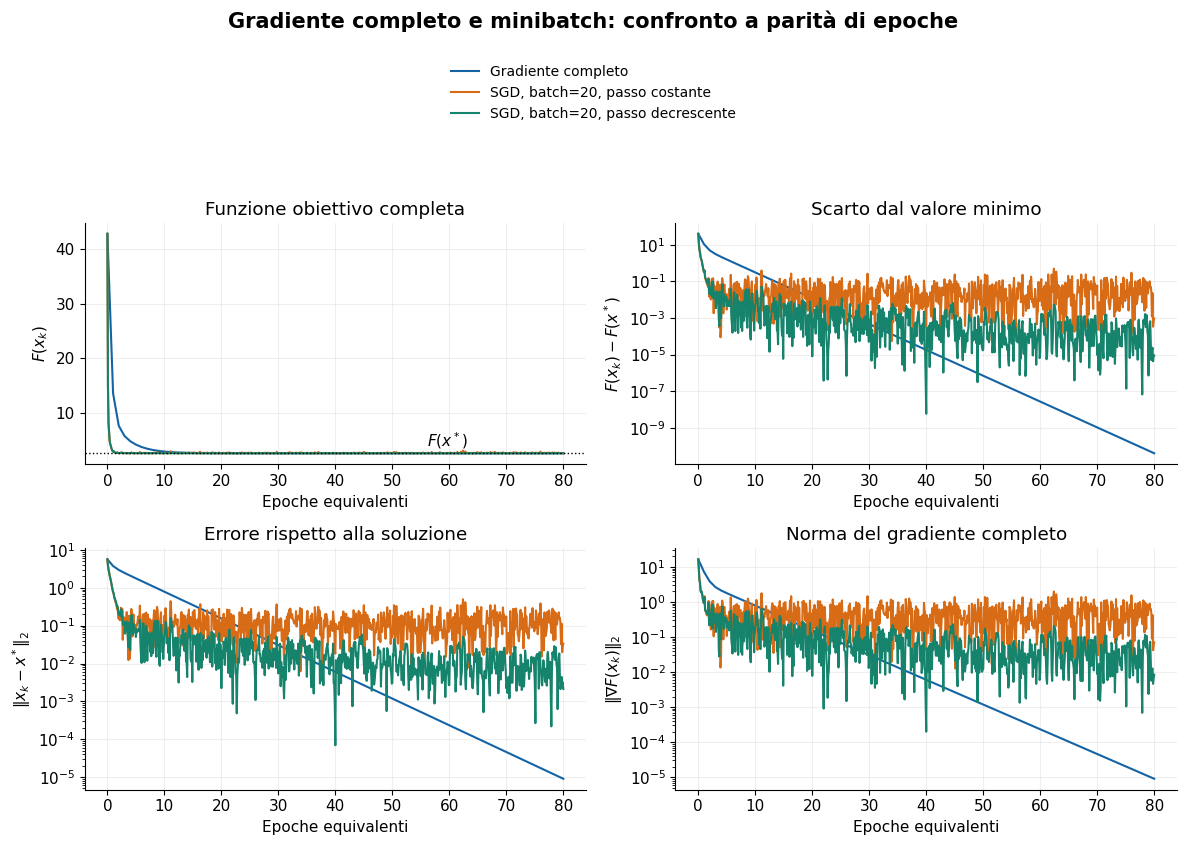

In [45]:
plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False})

fig, assi = plt.subplots(2, 2, figsize=(12, 8.5))
metriche = [
    ("F", "Funzione obiettivo completa", r"$F(x_k)$", False),
    ("gap", "Scarto dal valore minimo", r"$F(x_k)-F(x^*)$", True),
    ("errore", "Errore rispetto alla soluzione", r"$\|x_k-x^*\|_2$", True),
    ("norma_gradiente", "Norma del gradiente completo", r"$\|\nabla F(x_k)\|_2$", True)
]

for ax, (chiave, titolo, ylabel, log) in zip(assi.ravel(), metriche):
    for (nome, r), colore in zip(risultati.items(), colori):
        valori = np.maximum(r[chiave], 1e-16) if log else r[chiave]
        ax.plot(r["epoche"], valori, label=nome, color=colore, linewidth=1.5)
    if log:
        ax.set_yscale("log")
    ax.set_title(titolo)
    ax.set_xlabel("Epoche equivalenti")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.2)
assi[0, 0].axhline(F_star, color="black", linestyle=":", linewidth=1)
assi[0, 0].text(numero_epoche * 0.70, F_star + 1.2, r"$F(x^*)$", fontsize=11)
handles, labels = assi[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.94),
           ncol=1, frameon=False, fontsize=10)
fig.suptitle("Gradiente completo e minibatch: confronto a parità di epoche",
             fontsize=15, fontweight="bold", y=0.99)
fig.tight_layout(rect=(0, 0, 1, 0.83))
plt.show()

### 4. Le traiettorie sul piano

Le curve di livello rappresentano lo scarto $F(x)-F(x^*)$: avvicinandosi al centro delle ellissi ci si avvicina al minimo. Il pannello a destra ingrandisce la regione attorno a $x^*$ e aiuta a riconoscere le oscillazioni stocastiche.

Ogni segmento collega due iterati consecutivi. Il punto di partenza è uguale per tutti i metodi; il gradiente completo produce una traiettoria regolare, mentre SGD risente dei diversi minibatch.

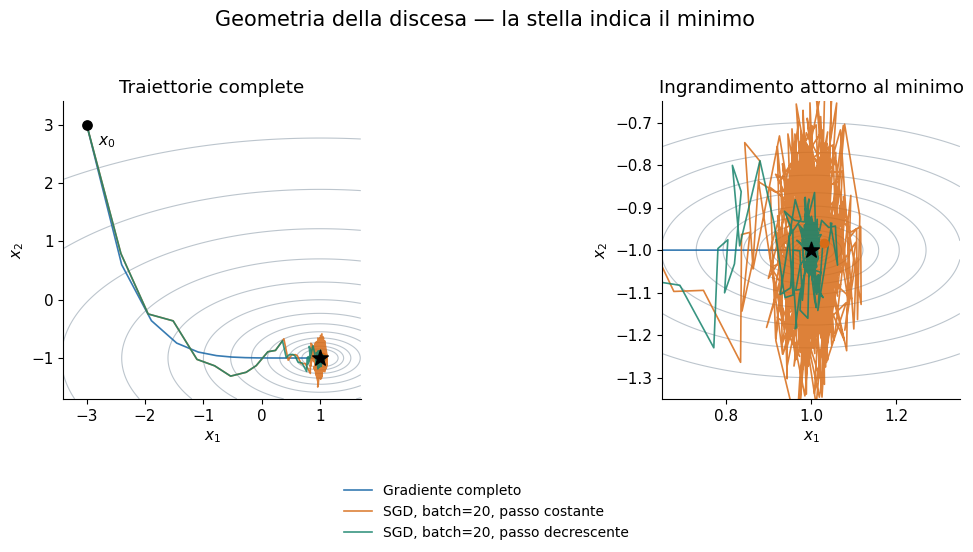

In [46]:
fig, assi = plt.subplots(1, 2, figsize=(12, 5.5))
finestre = [(-3.4, 1.7, -1.7, 3.4),
            (x_star[0] - 0.35, x_star[0] + 0.35,
             x_star[1] - 0.35, x_star[1] + 0.35)]

for ax, limiti, titolo in zip(assi, finestre,
                              ["Traiettorie complete", "Ingrandimento attorno al minimo"]):
    xmin, xmax, ymin, ymax = limiti
    xx, yy = np.meshgrid(np.linspace(xmin, xmax, 250),
                         np.linspace(ymin, ymax, 250))
    Z = 0.5 * (xx - x_star[0])**2 + 2 * (yy - x_star[1])**2
    livelli = np.geomspace(max(Z.max() * 0.001, 1e-6), Z.max(), 14)
    ax.contour(xx, yy, Z, levels=livelli, colors="#BCC5CD", linewidths=0.8)
    for (nome, r), colore in zip(risultati.items(), colori):
        X = r["x"]
        ax.plot(X[:, 0], X[:, 1], color=colore, linewidth=1.2,
                alpha=0.85, label=nome)
        ax.scatter(*X[-1], color=colore, s=35, zorder=4)
    ax.scatter(*x_star, marker="*", color="black", s=140, zorder=6)
    ax.set(xlim=(xmin, xmax), ylim=(ymin, ymax), xlabel=r"$x_1$", ylabel=r"$x_2$")
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(titolo)
assi[0].scatter(*x0, color="black", s=45, zorder=5)
assi[0].annotate(r"$x_0$", x0, xytext=(8, -15), textcoords="offset points")
fig.suptitle("Geometria della discesa — la stella indica il minimo", fontsize=15)
handles, labels = assi[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=1, frameon=False, fontsize=10)
fig.tight_layout(rect=(0, 0.16, 1, 0.95))
plt.show()

### 6. Risultati numerici e interpretazione

La tabella riporta i risultati alla fine dello stesso numero di epoche. Le ultime colonne misurano l'errore finale e l'errore medio nell'ultima epoca; quest'ultimo aiuta a non giudicare un metodo stocastico da un unico punto casualmente favorevole.

In [48]:
print(f"{'Metodo':<44} {'Update':>7} {'F finale':>12} {'Errore finale':>14} {'Errore medio*':>14}")
for nome, r in risultati.items():
    ultima_epoca = r["epoche"] > numero_epoche - 1
    print(f"{nome:<44} {len(r['x'])-1:7d} {r['F'][-1]:12.6f} "
          f"{r['errore'][-1]:14.3e} {r['errore'][ultima_epoca].mean():14.3e}")
print("* Media degli errori degli iterati prodotti nell'ultima epoca.")

Metodo                                        Update     F finale  Errore finale  Errore medio*
Gradiente completo                                80     2.709681      9.028e-06      9.028e-06
SGD, batch=20, passo costante                    800     2.710626      3.365e-02      1.051e-01
SGD, batch=20, passo decrescente                 800     2.709690      2.120e-03      6.145e-03
* Media degli errori degli iterati prodotti nell'ultima epoca.


Con i parametri iniziali si osserva che:

- **GD:** la funzione obiettivo diminuisce regolarmente e l'errore tende a zero. Per questa quadratica, $x_{k+1}-x^*=(I-\alpha_0H)(x_k-x^*)$; con $\alpha_0=0.15$, i fattori lungo gli assi sono $0.85$ e $0.4$, entrambi minori di uno in modulo.
- **SGD a passo costante:** sfrutta aggiornamenti economici e, a parità di epoche, può avvicinarsi rapidamente al minimo. In seguito rimangono oscillazioni; la funzione completa può aumentare fra due aggiornamenti.
- **SGD a passo decrescente:** riducendo il passo si attenuano le oscillazioni e, in questo esperimento, si migliora l'accuratezza finale rispetto al passo costante. Una riduzione troppo rapida può però rallentare l'avvicinamento al minimo.
- **Funzione obiettivo ed errore non sono la stessa quantità:** qui vale $F(x)-F(x^*)=\frac12(x-x^*)^TH(x-x^*)$, quindi lo scarto è quadratico nella distanza dal minimo. Il valore $F(x_k)$ può apparire quasi costante anche quando l'errore sta ancora cambiando.

Le curve stocastiche mostrate corrispondono a **una sola realizzazione riproducibile**. Cambiando `seed_batch` cambiano le oscillazioni; non si tratta di un confronto statistico su più esecuzioni.

### Esperimenti per gli studenti

1. Impostare `batch_size = 1`, poi `20`, `100` e infine `N`. Osservare oscillazioni e numero di aggiornamenti per epoca. Con `batch_size = N`, SGD a passo costante coincide con GD, salvo arrotondamenti.
2. Cambiare `alpha0` da `0.15` a `0.05` oppure `0.30`: come cambiano le traiettorie e la velocità del gradiente completo?
3. Cambiare `scala_decay`: un valore piccolo riduce il passo prima; un valore grande lo mantiene alto più a lungo.
4. Spiegare perché un piccolo gradiente di un singolo minibatch non basta per concludere che si è raggiunto il minimo della funzione completa.

Il **gradiente stocastico è utile soprattutto quando calcolare il gradiente completo è costoso**. Il suo vantaggio principale è poter aggiornare i parametri usando pochi dati, accettando una direzione meno precisa.

**Convergenza del gradiente completo.** Il metodo utilizza a ogni iterazione tutta l’informazione disponibile. Con opportune ipotesi di regolarità e una scelta adeguata del passo, la funzione obiettivo diminuisce. Nel caso fortemente convesso, come nella quadratica dell’esempio, converge all’unico minimo globale e, con un passo costante opportuno, l’errore diminuisce geometricamente:
\[
\|x_k-x^*\|\leq C\rho^k,\qquad 0<\rho<1.
\]
Per funzioni non convesse, invece, le garanzie riguardano generalmente il raggiungimento della stazionarietà, non del minimo globale.

**Convergenza del gradiente stocastico.** Il gradiente calcolato su un minibatch contiene una componente di variabilità dovuta al campionamento. Di conseguenza, **la funzione obiettivo completa non deve necessariamente diminuire a ogni aggiornamento**: occasionali aumenti sono compatibili con un progresso complessivo verso il minimo.

Con un **passo costante**, il metodo può avvicinarsi rapidamente alla soluzione, ma in presenza di rumore persistente tende a mantenere oscillazioni attorno al minimo. In termini di errore medio, si osserva spesso un livello residuo: un passo più piccolo può ridurlo, ma rallenta l’avvicinamento iniziale. Questo comportamento non è inevitabile in ogni problema: se anche i gradienti dei singoli termini si annullano al minimo, il rumore può scomparire.

Con un **passo decrescente**, l’effetto degli aggiornamenti casuali viene progressivamente attenuato. Nel quadro classico del campionamento indipendente, sotto opportune ipotesi sulla funzione e sulla variabilità del gradiente, condizioni come
\[
\sum_k\alpha_k=\infty,
\qquad
\sum_k\alpha_k^2<\infty
\]
consentono di ottenere risultati di convergenza. La prima evita che i passi si riducano troppo rapidamente; la seconda limita l’effetto cumulativo del rumore.

**Ruolo del minibatch.** Un minibatch piccolo rende gli aggiornamenti economici ma più variabili; aumentandolo si ottiene una stima più precisa, con un costo maggiore per aggiornamento. La scelta è quindi un compromesso fra costo, variabilità e possibilità di sfruttare il calcolo parallelo.





### Vantaggi

- Ogni aggiornamento ha costo ridotto.
- È adatto a dataset molto grandi.
- Può essere usato quando i dati arrivano progressivamente.
- Il rumore può aiutare a non arrestarsi in regioni quasi piatte o vicino ad alcuni punti di sella.

### Limiti

- La funzione obiettivo non necessariamente diminuisce a ogni iterazione.
- Gli iterati seguono una traiettoria oscillante.
- La scelta del learning rate è delicata.
- La convergenza è generalmente meno regolare di quella del gradiente completo.